# Bibliotèque MKL sur Python

dy/dt = -y

In [66]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

In [2]:
np.__config__.show()

Build Dependencies:
  blas:
    detection method: system
    found: true
    include directory: unknown
    lib directory: unknown
    name: blas
    openblas configuration: unknown
    pc file directory: unknown
    version: unknown
  lapack:
    detection method: internal
    found: true
    include directory: unknown
    lib directory: unknown
    name: dep140228583157936
    openblas configuration: unknown
    pc file directory: unknown
    version: 1.26.4
Compilers:
  c:
    args: -g, -O2, -fno-omit-frame-pointer, -mno-omit-leaf-frame-pointer, -ffile-prefix-map=/build/numpy-VpSPb5/numpy-1.26.4+ds=.,
      -flto=auto, -ffat-lto-objects, -fstack-protector-strong, -fstack-clash-protection,
      -Wformat, -Werror=format-security, -fcf-protection, -fdebug-prefix-map=/build/numpy-VpSPb5/numpy-1.26.4+ds=/usr/src/numpy-1:1.26.4+ds-6ubuntu1,
      -Wdate-time, -D_FORTIFY_SOURCE=3
    commands: cc
    linker: ld.bfd
    linker args: -Wl,-Bsymbolic-functions, -flto=auto, -ffat-lto-objects, 

dy/dt = -y

In [64]:
A = np.array([
    [1, 2, 3],
    [4, 5, 1],
    [0, 2, 3]
])
np.dot?

Call signature:  np.dot(*args, **kwargs)
Type:            _ArrayFunctionDispatcher
String form:     <built-in function dot>
Docstring:      
dot(a, b, out=None)

Dot product of two arrays. Specifically,

- If both `a` and `b` are 1-D arrays, it is inner product of vectors
  (without complex conjugation).

- If both `a` and `b` are 2-D arrays, it is matrix multiplication,
  but using :func:`matmul` or ``a @ b`` is preferred.

- If either `a` or `b` is 0-D (scalar), it is equivalent to
  :func:`multiply` and using ``numpy.multiply(a, b)`` or ``a * b`` is
  preferred.

- If `a` is an N-D array and `b` is a 1-D array, it is a sum product over
  the last axis of `a` and `b`.

- If `a` is an N-D array and `b` is an M-D array (where ``M>=2``), it is a
  sum product over the last axis of `a` and the second-to-last axis of
  `b`::

    dot(a, b)[i,j,k,m] = sum(a[i,j,:] * b[k,:,m])

It uses an optimized BLAS library when possible (see `numpy.linalg`).

Parameters
----------
a : array_like
    Fi

In [6]:
def f(t, y):
    return -y

In [7]:
t_span = (0, 100)
y0 = [1]

sol = solve_ivp(f, t_span, y0, method="RK45")

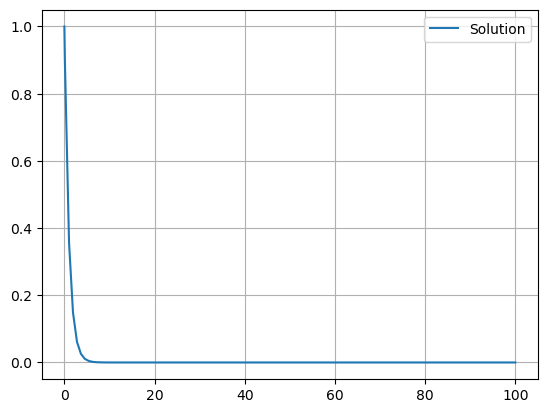

In [8]:
plt.plot(sol.t, sol.y[0], label="Solution")
plt.legend()
plt.grid()


---
# <center style="color: orange; font-weight: bold; font-size: 2rem;">Équation de la chaleur et méthode des différences finies</center>

L’équation de la chaleur est une équation aux dérivées partielles (EDP) qui modélise la diffusion de la chaleur dans un milieu. Elle s’écrit sous la forme :

$$ \frac{\partial u}{\partial t} = \alpha \frac{\partial^2 u}{\partial x^2} $$

où :  
- \( u(x, t) \) représente la température en un point \( x \) et à l’instant \( t \),  
- \( \alpha \) est le coefficient de diffusion thermique.

## Discrétisation par la méthode des différences finies

On approxime les dérivées par des différences finies :

- **Dérivée temporelle (avance d’Euler) :**  
  $$ \frac{\partial u}{\partial t} \approx \frac{u_i^{n+1} - u_i^n}{\Delta t} $$
  
- **Dérivée spatiale (centrée) :**  
  $$ \frac{\partial^2 u}{\partial x^2} \approx \frac{u_{i+1}^n - 2u_i^n + u_{i-1}^n}{\Delta x^2} $$

En remplaçant ces approximations dans l’équation de la chaleur, on obtient le schéma explicite :

$$ u_i^{n+1} = u_i^n + \frac{\alpha \Delta t}{\Delta x^2} (u_{i+1}^n - 2u_i^n + u_{i-1}^n) $$

Ce schéma est stable sous la condition de Courant-Friedrichs-Lewy (CFL) :

$$ \frac{\alpha \Delta t}{\Delta x^2} \leq \frac{1}{2} $$

Cette méthode permet de résoudre numériquement l'équation de la chaleur en itérant sur \( t \) pour obtenir la distribution de température au fil du temps.

---


### Méthode des Différences finies explicites
- Simulation sur une barre avec un temps total de 1.2s: X = (x)

In [47]:
import time

Temps d'exécution:  0.0055217742919921875


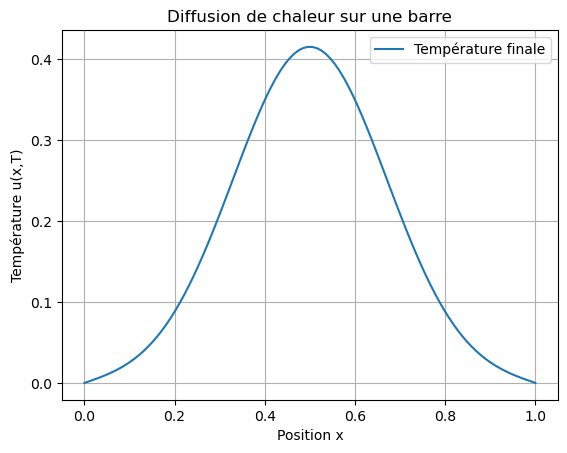

In [52]:
t1 = time.time()
# Paramètres physiques
L = 1.0  # Longueur de la barre
T = 1.2  # Temps total de simulation
alpha = 0.01  # Coefficient de diffusion thermique
# Discrétisation
N = 100  # Nombre de points spatiaux
dx = L / (N - 1)  # Pas spatial
dt = 0.4 * dx**2 / alpha  # Pas temporel respectant CFL
Nt = int(T / dt)  # Nombre de pas temporels

# Grille spatiale et condition initiale (ex: gaussienne)
x = np.linspace(0, L, N)
u = np.exp(-100 * (x - L/2) ** 2)  # Pic initial

# Matrice de discrétisation (Méthode des Différences Finies)
r = alpha * dt / dx**2
A = np.diag((1 - 2 * r) * np.ones(N)) + np.diag(r * np.ones(N-1), k=1) + np.diag(r * np.ones(N-1), k=-1)

# Conditions aux bords (Dirichlet : Température fixe)
A[0, :] = A[-1, :] = 0
A[0, 0] = A[-1, -1] = 1

# Simulation
for _ in range(Nt):
    u = np.dot(A, u)  # Utilisation de MKL via numpy.dot()

print("Temps d'exécution: ", time.time() - t1)
# Affichage du résultat final
plt.plot(x, u, label="Température finale")
plt.xlabel("Position x")
plt.ylabel("Température u(x,T)")
plt.title("Diffusion de chaleur sur une barre")
plt.legend()
plt.grid()
plt.show()


Temps dexécution:  0.0736837387084961


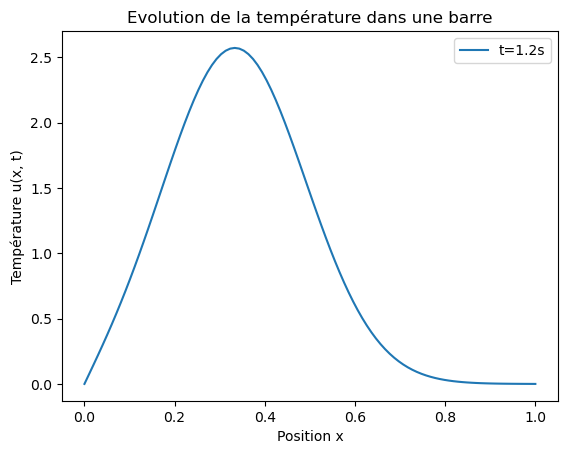

In [53]:
t1 = time.time()
L = 1
Nx = 100
dx = L / Nx
alpha = 0.01

Tmax = 1.2 # Temps de simulation
dt = 0.4 * dx**2 / alpha
#dt = 5e-4
Nt = int(Tmax / dt)

u = np.zeros(Nx)
u[int(Nx/3)] = 100.0
for n in range(Nt):
    u_new = u.copy()
    for i in range(1, Nx - 1):
        u_new[i] = u[i] + alpha * dt / dx**2 * (u[i+1] -2*u[i] + u[i-1])

    u = u_new

print("Temps dexécution: ", time.time() - t1)
plt.plot(np.linspace(0, L, Nx), u, label=f"t={Tmax}s")
plt.xlabel("Position x")
plt.ylabel("Température u(x, t)")
plt.title("Evolution de la température dans une barre")
plt.legend()


---
# <center style="color: orange; font-weight: bold; font-size: 2rem;">Modèle épidémiologique SIR et résolution numérique</center>

Le modèle **SIR (Susceptible - Infected - Recovered)** est utilisé pour modéliser la propagation d’une épidémie. Il est défini par le système d’équations différentielles suivantes :

$
\frac{dS}{dt} = -\beta S I
$

$
\frac{dI}{dt} = \beta S I - \gamma I
$

$
\frac{dR}{dt} = \gamma I
$

où :
- \( S(t) \) : Nombre d’individus susceptibles,
- \( I(t) \) : Nombre d’individus infectés,
- \( R(t) \) : Nombre d’individus guéris,
- \( $\beta $\) : Taux de transmission,
- \( $\gamma$ \) : Taux de récupération.

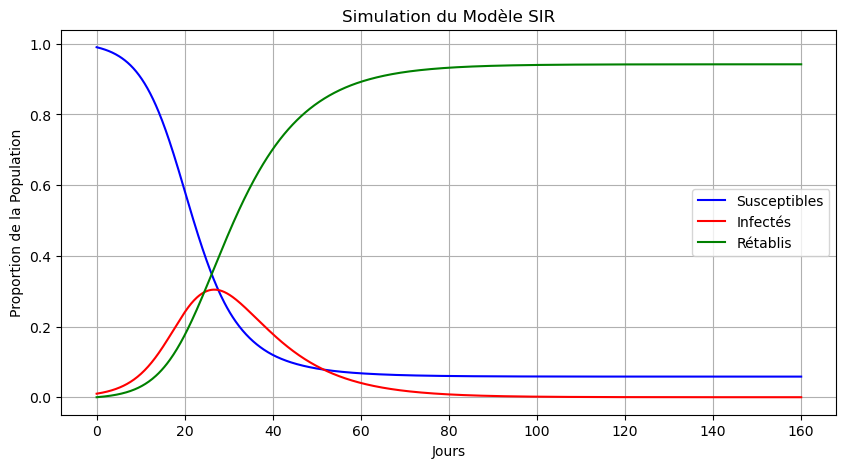

In [60]:
# Définition du modèle SIR
def sir_model(t, y, beta, gamma):
    S, I, R = y  # Extraction des variables
    dSdt = -beta * S * I  # Variation des susceptibles
    dIdt = beta * S * I - gamma * I  # Variation des infectés
    dRdt = gamma * I  # Variation des rétablis
    return [dSdt, dIdt, dRdt]

# Paramètres du modèle
beta = 0.3   # Taux d'infection
gamma = 0.1  # Taux de guérison

# Conditions initiales
S0 = 0.99  # 99% de la population est susceptible
I0 = 0.01  # 1% de la population est infectée
R0 = 0.0   # Aucun rétabli au début

# Période de simulation
t_span = (0, 160)  # Simulation sur 160 jours
t_eval = np.linspace(t_span[0], t_span[1], 1000)  # Points de temps pour l'évaluation

# Résolution numérique des équations
solution = solve_ivp(
    sir_model, t_span, [S0, I0, R0], args=(beta, gamma), t_eval=t_eval
)

# Extraction des résultats
S, I, R = solution.y

# Tracé des courbes
plt.figure(figsize=(10, 5))
plt.plot(solution.t, S, label="Susceptibles", color='blue')
plt.plot(solution.t, I, label="Infectés", color='red')
plt.plot(solution.t, R, label="Rétablis", color='green')
plt.xlabel("Jours")
plt.ylabel("Proportion de la Population")
plt.title("Simulation du Modèle SIR")
plt.legend()
plt.grid()
plt.show()

 ---
# <center style="color: orange; font-weight: bold; font-size: 2rem;">Modèle Proie-Prédateur</center>

In [31]:
import scipy

In [32]:
scipy.show_config()

Build Dependencies:
  blas:
    detection method: pkgconfig
    found: true
    include directory: /usr/include/x86_64-linux-gnu
    lib directory: /usr/lib/x86_64-linux-gnu
    name: blas
    openblas configuration: unknown
    pc file directory: /usr/lib/x86_64-linux-gnu/pkgconfig
    version: 3.12.0
  lapack:
    detection method: pkgconfig
    found: true
    include directory: /usr/include/x86_64-linux-gnu
    lib directory: /usr/lib/x86_64-linux-gnu
    name: lapack
    openblas configuration: unknown
    pc file directory: /usr/lib/x86_64-linux-gnu/pkgconfig
    version: 3.12.0
  pybind11:
    detection method: pkgconfig
    include directory: /usr/include
    name: pybind11
    version: 2.11.1
Compilers:
  c:
    commands: cc
    linker: ld.bfd
    name: gcc
    version: 13.2.0
  c++:
    commands: c++
    linker: ld.bfd
    name: gcc
    version: 13.2.0
  cython:
    commands: cython3
    linker: cython
    name: cython
    version: 0.29.37
  fortran:
    commands: gfortran
  

In [15]:
from scipy.integrate import odeint

In [17]:
def model(population, t, params):
    x = population[0]
    y = population[1]
    
    a = params[0]
    b = params[1]
    c = params[2]
    d = params[3]
    
    dx = a*x - b*x*y
    dy = d*x*y - c*y
    return [dx, dy]

In [27]:
population = [10, 3] # 10 Proies et 3 prédateurs dans la région au début de l'expérience
t = np.linspace(0, 30, 1000)
a = 1.1
b = 0.4
d = 0.1
c = 0.4
params = [a, b, c, d]

In [29]:
y = odeint(model, population, t, args=(params, ))

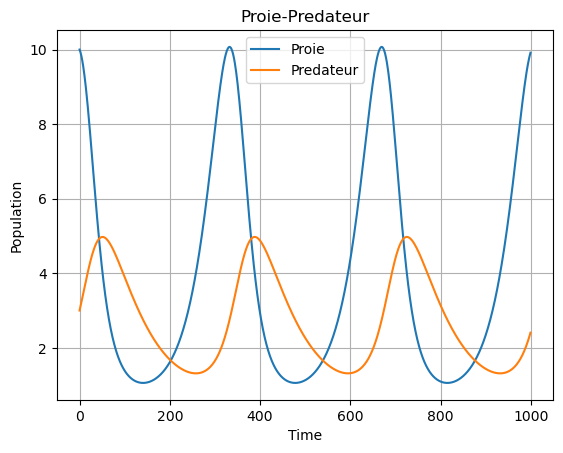

In [30]:
plt.plot(y)
plt.xlabel("Time")
plt.ylabel("Population")
plt.title("Proie-Predateur")
plt.legend(["Proie", "Predateur"])
plt.grid()
plt.savefig("prey.png")

In [62]:
import sklearn

In [63]:
sklearn.show_versions()


System:
    python: 3.12.3 (main, Jan 17 2025, 18:03:48) [GCC 13.3.0]
executable: /usr/bin/python3
   machine: Linux-6.8.0-41-generic-x86_64-with-glibc2.39

Python dependencies:
      sklearn: 1.4.1.post1
          pip: 24.0
   setuptools: 68.1.2
        numpy: 1.26.4
        scipy: 1.11.4
       Cython: None
       pandas: 2.1.4+dfsg
   matplotlib: 3.6.3
       joblib: 1.3.2
threadpoolctl: 3.1.0

Built with OpenMP: True

threadpoolctl info:
       user_api: blas
   internal_api: mkl
         prefix: libmkl_rt
       filepath: /usr/lib/x86_64-linux-gnu/libmkl_rt.so
        version: 2020.0.4
threading_layer: intel
    num_threads: 2

       user_api: openmp
   internal_api: openmp
         prefix: libomp
       filepath: /usr/lib/llvm-18/lib/libomp.so.5
        version: None
    num_threads: 4

       user_api: openmp
   internal_api: openmp
         prefix: libgomp
       filepath: /usr/lib/x86_64-linux-gnu/libgomp.so.1.0.0
        version: None
    num_threads: 4


In [68]:
import ctypes
import numpy as np

# Charger MKL
mkl = ctypes.cdll.LoadLibrary("libmkl_rt.so")

# Définir la fonction LAPACK dgetrf (factorisation LU)
dgetrf = mkl.LAPACKE_dgetrf  # Utiliser LAPACKE_dgetrf pour simplifier
dgetrf.restype = ctypes.c_int
dgetrf.argtypes = [ctypes.c_int, ctypes.c_int, ctypes.c_int, 
                   ctypes.POINTER(ctypes.c_double), ctypes.c_int, 
                   ctypes.POINTER(ctypes.c_int)]

# Créer une matrice
A = np.array([[4, 3], [6, 3]], dtype=np.float64, order='F')  # Matrice en column-major

# Pointeurs pour LAPACK
n = A.shape[0]  # Taille de la matrice
ipiv = np.zeros(n, dtype=np.int32)  # Tableau pour pivots

# Appeler la fonction LAPACK
info = dgetrf(101, n, n, A.ctypes.data_as(ctypes.POINTER(ctypes.c_double)), n, ipiv.ctypes.data_as(ctypes.POINTER(ctypes.c_int)))

if info == 0:
    print("Factorisation LU réussie !")
    print("Matrice après factorisation LU :\n", A)
    print("Pivots :", ipiv)
else:
    print(f"Erreur dans dgetrf : info = {info}")

Factorisation LU réussie !
Matrice après factorisation LU :
 [[ 4.    0.75]
 [ 6.   -1.5 ]]
Pivots : [1 2]
